# Thông tin sinh viên

*   MSSV: 23520199
*   Họ và tên: Nguyễn Chí Cường



#Bài tập 5: Phân loại ảnh sử dụng mạng tích chập CNN

#Kết nối/ Mount đến Google Drive

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


#Khai báo thư viện

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

from tensorflow.keras import datasets, layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam, SGD

from sklearn.model_selection import train_test_split

# Đọc dữ liệu

In [8]:
# Hàm đọc dữ liệu từ thư mục folder
def load_images_from_folder(folder, img_rows, img_cols):
    images = []
    labels = []
    class_names = sorted(os.listdir(folder))

    for label, class_name in enumerate(class_names):
        class_folder = os.path.join(folder, class_name)
        print(f"Processing class: {class_name}")
        if os.path.isdir(class_folder):
            for filename in os.listdir(class_folder):
                img_path = os.path.join(class_folder, filename)
                img = cv2.imread(img_path)
                if img is not None:
                    img = cv2.resize(img, (img_rows, img_cols))
                    images.append(img)
                    labels.append(label)

    return images, labels, class_names

In [9]:
# Đọc dữ liệu từ thư mục Dataset
train_folder = "/content/drive/MyDrive/HoaVietNam/train"
test_folder = "/content/drive/MyDrive/HoaVietNam/test"

img_rows, img_cols = 128, 128


training_images, training_labels, class_names = load_images_from_folder(
    train_folder, img_rows, img_cols
)
test_images, test_labels, _ = load_images_from_folder(test_folder, img_rows, img_cols)

Processing class: Cuc
Processing class: Dao
Processing class: Lan
Processing class: Mai
Processing class: Sen
Processing class: Tho
Processing class: Cuc
Processing class: Dao
Processing class: Lan
Processing class: Mai
Processing class: Sen
Processing class: Tho


##  Chia tập dữ liệu

In [10]:
train_images, validation_images, train_labels, validation_labels = train_test_split(
    training_images, training_labels, test_size=1 / 3, train_size=2 / 3, random_state=42
)

## Xử lý dữ liệu

In [11]:
train_images = np.array(train_images)
validation_images = np.array(validation_images)
test_images = np.array(test_images)

# Chuyển đổi miền giá trị
train_images = (
    train_images.reshape((len(train_images), img_rows, img_cols, 3)).astype("float32")
    / 255
)
validation_images = (
    validation_images.reshape((len(validation_images), img_rows, img_cols, 3)).astype(
        "float32"
    )
    / 255
)
test_images = (
    test_images.reshape((len(test_images), img_rows, img_cols, 3)).astype("float32")
    / 255
)


train_labels = to_categorical(train_labels)
validation_labels = to_categorical(validation_labels)
test_labels = to_categorical(test_labels)

In [12]:
print(f"Kích thước tập train: {train_images.shape}, {train_labels.shape}")
print(
    f"Kích thước tập validation: {validation_images.shape}, {validation_labels.shape}"
)
print(f"Kích thước tập test: {test_images.shape}, {test_labels.shape}")

Kích thước tập train: (140, 128, 128, 3), (140, 6)
Kích thước tập validation: (70, 128, 128, 3), (70, 6)
Kích thước tập test: (62, 128, 128, 3), (62, 6)


In [13]:
validation_labels

array([[1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1.],
       [0., 1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0.],
       [0., 1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1.],
       [0., 0., 0., 1., 0., 0.],
       [0., 0., 0., 0., 0., 1.],
       [0., 0., 0., 0., 0., 1.],
       [0., 0., 0., 1., 0., 0.],
       [1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 1., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 1., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0.],
       [1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0.],
       [0.

## Khai báo mạng CNN

In [14]:
model = models.Sequential()

model.add(
    layers.Conv2D(
        6,
        (3, 3),
        activation="relu",
        input_shape=(img_rows, img_cols, 3),
        padding="same",
    )
)
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(16, (3, 3), activation="relu", padding="same"))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Flatten())
model.add(layers.Dense(120, activation="relu"))
model.add(layers.Dense(84, activation="relu"))
model.add(layers.Dense(6, activation="softmax"))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
# Compile the model
opt = Adam(learning_rate=0.00001)
model.compile(optimizer=opt, loss="categorical_crossentropy", metrics=["accuracy"])

In [16]:
# Display model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 6)    │           168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 16)     │           880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │     1,966,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,977,922 (7.55 MB)

 Trainable params: 1,977,922 (7.55 MB)

 Non-trainable params: 0 (0.00 B)

# Yêu cầu 1
* Thực hiện huấn luyện mô hình
* Hiển thị biểu đồ cho biết Độ chính xác và loss trong quá trình huấn luyện

## Huấn luyện mô hình

In [18]:
# Train the model with validation data
history = model.fit(
    train_images,
    train_labels,
    epochs=15,
    batch_size=8,
    validation_data=(validation_images, validation_labels),
)

Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 158ms/step - accuracy: 0.2469 - loss: 1.7731 - val_accuracy: 0.3429 - val_loss: 1.7172
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2974 - loss: 1.7252 - val_accuracy: 0.3714 - val_loss: 1.6740
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3621 - loss: 1.6788 - val_accuracy: 0.4429 - val_loss: 1.6336
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4113 - loss: 1.6212 - val_accuracy: 0.5000 - val_loss: 1.5872
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5219 - loss: 1.5331 - val_accuracy: 0.4714 - val_loss: 1.5413
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5220 - loss: 1.4642 - val_accuracy: 0.5143 - val_loss: 1.5018
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4711 - loss: 1.4856 - val_accuracy: 0.5571 - val_loss: 1.4675
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6176 - loss: 1.3746 - val_accuracy: 0.5571 - val_los

## Thông tin quá trình huấn luyện

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


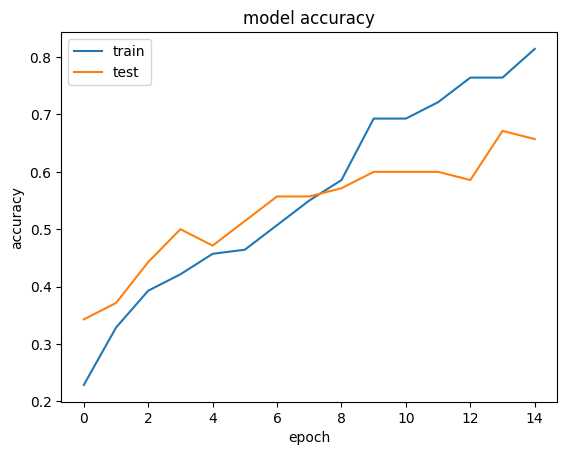

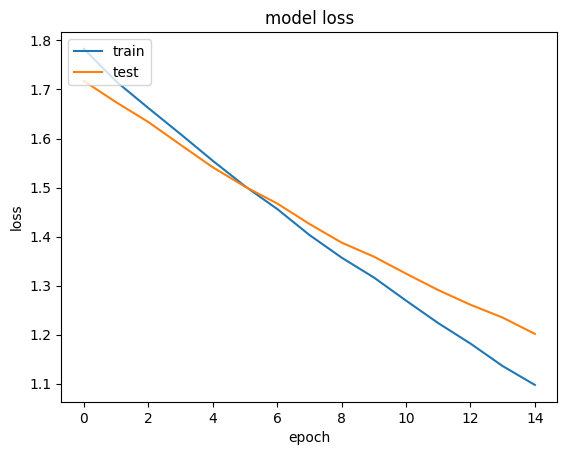

In [19]:
# list all data in history
print(history.history.keys())
# summarize history for accuracy
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("model accuracy")
plt.ylabel("accuracy")
plt.xlabel("epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()
# summarize history for loss
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("model loss")
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

# Yêu cầu 2
* Đánh giá kết quả của mô hình trên tập Test
* Sử dụng hàm classification_report để in ra kết quả phân loại của hai mô hình.


#Đánh giá kết quả

In [20]:
# Testing the model on test data
test_loss, test_accuracy = model.evaluate(test_images, test_labels, verbose=2)
print(f"Test Accuracy: {test_accuracy}")
print(f"Test Loss: {test_loss}")

2/2 - 2s - 787ms/step - accuracy: 0.5968 - loss: 1.2606
Test Accuracy: 0.5967742204666138
Test Loss: 1.260572910308838


In [21]:
train_labels.shape

(140, 6)

## In ra kết quả phân loại

In [22]:
# Predicting labels for test images
predicted_labels = np.argmax(model.predict(test_images), axis=-1)
# Display classification report
print(
    "Classification Report:\n",
    classification_report(np.argmax(test_labels, axis=-1), predicted_labels),
)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 332ms/step
Classification Report:
               precision    recall  f1-score   support

           0       0.47      0.80      0.59        10
           1       0.82      0.75      0.78        12
           2       0.71      0.50      0.59        10
           3       1.00      0.20      0.33        10
           4       0.57      0.40      0.47        10
           5       0.50      0.90      0.64        10

    accuracy                           0.60        62
   macro avg       0.68      0.59      0.57        62
weighted avg       0.68      0.60      0.58        62

